# How Republicans Won the Share: Switchers, New Voters, and What They Believed

Part 7 established that the 2024 loss in swing states came through share, not turnout. This notebook decomposes the share shift into its two sources — Biden 2020 voters who switched, and 2020 non-voters who entered for Trump — and then asks what those two groups believed on the policy items the 2024 CES carries.

**The hypothesis under test:** Harris lost economically-left but culturally-conservative voters by accepting a culture-war framing rather than pivoting to economic populism. The CES cannot measure messaging. It can measure (a) whether switchers and new Trump voters held Democratic-aligned economic views, (b) whether they held conservative cultural views, (c) which axis better predicts the vote, and (d) how far left they perceived Harris to be and what that perception tracked.

**What the 2024 CES asks** (support/oppose): Medicaid expansion, ACA repeal, Medicaid work requirements, student-loan forgiveness, corporate tax to 28%, tax on $400k+, extending the 2017 cuts, low-income housing incentives; the border wall, asylum denial, more border patrol, legal status for long-employed immigrants, Dreamers; abortion as a matter of choice, federal recognition of same-sex marriage; more police / defund. Plus 7-point ideological placement of self, Harris, and Trump.

**What it does not ask:** anything on transgender policy, "wokeness," minimum wage, Medicare-for-all, tariffs, or issue salience. Those parts of the hypothesis are untestable here.

**Inputs:** `data/raw/ces/CCES24_Common_OUTPUT_vv_topost_final.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
RAW_DIR = Path('../data/raw'); TABLES_DIR = Path('../outputs/tables'); FIGURES_DIR = Path('../outputs/figures')
def wmean(x, w):
    m = x.notna() & w.notna()
    return np.average(x[m], weights=w[m]) if m.any() else np.nan

cols = ['caseid', 'countyfips', 'TS_g2024', 'vvweight_post', 'vvweight', 'presvote20post', 'CC24_410', 'pid7', 'birthyr', 'educ', 'race', 'hispanic', 'faminc_new',
        'CC24_321d', 'CC24_321e', 'CC24_323a', 'CC24_323b', 'CC24_323c', 'CC24_323d', 'CC24_323f', 'CC24_324a',
        'CC24_328b', 'CC24_328c', 'CC24_328d', 'CC24_328e', 'CC24_330a', 'CC24_330d', 'CC24_330e', 'CC24_340c', 'CC24_340f', 'CC24_341a', 'CC24_341b', 'CC24_341c']
d = pd.read_csv(RAW_DIR / 'ces' / 'CCES24_Common_OUTPUT_vv_topost_final.csv', usecols=cols, low_memory=False)
sup = lambda c: (d[c] == 1).astype(float).where(d[c].notna())
opp = lambda c: (d[c] == 2).astype(float).where(d[c].notna())

# Item-level indicators: 1 = the Democratic-aligned / liberal position
items = pd.DataFrame({
    'expand_medicaid': sup('CC24_328e'), 'keep_ACA': opp('CC24_328d'), 'no_medicaid_workreq': opp('CC24_328c'), 'student_loans': sup('CC24_323f'),
    'corp_tax_28': sup('CC24_341b'), 'tax_400k': sup('CC24_341c'), 'no_2017_cuts': opp('CC24_341a'), 'housing_subsidy': sup('CC24_328b'),
    'no_wall': opp('CC24_323c'), 'allow_asylum': opp('CC24_340f'), 'no_more_border_patrol': opp('CC24_323b'), 'legal_status': sup('CC24_323a'), 'dreamers': sup('CC24_323d'),
    'abortion_choice': sup('CC24_324a'), 'samesex_marriage': sup('CC24_340c'), 'no_more_police': opp('CC24_321d'), 'defund': sup('CC24_321e')})
ECON = ['expand_medicaid', 'keep_ACA', 'no_medicaid_workreq', 'student_loans', 'corp_tax_28', 'tax_400k', 'no_2017_cuts', 'housing_subsidy']
IMMIG = ['no_wall', 'allow_asylum', 'no_more_border_patrol', 'legal_status', 'dreamers']
SOCIAL = ['abortion_choice', 'samesex_marriage']
POLICE = ['no_more_police', 'defund']
d['econ_left']   = items[ECON].mean(axis=1)
d['immig_cons']  = 1 - items[IMMIG].mean(axis=1)
d['social_cons'] = 1 - items[SOCIAL].mean(axis=1)
d['police_cons'] = 1 - items[POLICE].mean(axis=1)
d['cult_cons']   = 1 - items[IMMIG + SOCIAL + POLICE].mean(axis=1)

d['voted24'] = d['TS_g2024'].notna() & (d['TS_g2024'] != 7)
d['v20'] = d['presvote20post'].map({1: 'Biden', 2: 'Trump', 3: 'other', 4: 'other', 5: 'other', 6: 'nonvoter'})
d['v24'] = np.select([d['CC24_410'] == 1, d['CC24_410'] == 2, d['CC24_410'].between(3, 7)], ['Harris', 'Trump', 'third'], None)
e = d[d['voted24'] & d['v24'].notna() & d['v20'].notna()].copy()
e['wt'] = e['vvweight_post'].fillna(e['vvweight'])
e['path'] = e['v20'] + '->' + e['v24']
for c in ['CC24_330a', 'CC24_330d', 'CC24_330e']:
    e[c] = e[c].where(e[c] <= 7)
e['self_ideo'] = e['CC24_330a']; e['harris_ideo'] = e['CC24_330d']; e['trump_ideo'] = e['CC24_330e']
e['harris_very_lib'] = (e['harris_ideo'] == 1).astype(float).where(e['harris_ideo'].notna())
e['dist_harris'] = (e['harris_ideo'] - e['self_ideo']).abs(); e['dist_trump'] = (e['trump_ideo'] - e['self_ideo']).abs()
e['age'] = 2024 - e['birthyr']; e['college'] = (e['educ'] >= 5).astype(int)
e['hisp'] = (e['hispanic'] == 1).astype(int); e['black'] = ((e['race'] == 2) & (e['hispanic'] != 1)).astype(int)
e['pid7c'] = e['pid7'].where(e['pid7'] <= 7)
e['lowinc'] = (e['faminc_new'].where(e['faminc_new'] <= 16) <= 5).astype(float).where(e['faminc_new'] <= 16)
for v in ['econ_left', 'immig_cons', 'social_cons', 'police_cons', 'cult_cons']:
    e[v + '_z'] = (e[v] - e[v].mean()) / e[v].std()
e = e.join(items, rsuffix='_item')
print(f'Validated 2024 voters with a 2024 vote and a recalled 2020 status: {len(e):,}')

Validated 2024 voters with a 2024 vote and a recalled 2020 status: 32,531


## 1. Decomposition of the 2024 share shift

In [2]:
W = e['wt'].sum()
rows = []
for s in ['Biden', 'Trump', 'other', 'nonvoter']:
    g = e[e['v20'] == s]; sh = g['wt'].sum() / W
    h, t, o = [wmean((g['v24'] == k).astype(float), g['wt']) for k in ['Harris', 'Trump', 'third']]
    rows.append({'2020 status': s, 'N': len(g), 'share_of_2024_voters': sh, 'Harris': h, 'Trump': t, 'third': o, 'net_to_Trump_pp': sh * (t - h) * 100})
decomp = pd.DataFrame(rows).set_index('2020 status')
print(decomp.round(3).to_string())
b = e[e['v20'] == 'Biden']; t = e[e['v20'] == 'Trump']; n = e[e['v20'] == 'nonvoter']
sB, sT, sN = b['wt'].sum() / W, t['wt'].sum() / W, n['wt'].sum() / W
bt = wmean((b['v24'] == 'Trump').astype(float), b['wt']); th = wmean((t['v24'] == 'Harris').astype(float), t['wt'])
nh, nt = wmean((n['v24'] == 'Harris').astype(float), n['wt']), wmean((n['v24'] == 'Trump').astype(float), n['wt'])
print(f'\nBiden->Trump: {sB * bt * 100:+.2f}pp   Trump->Harris: {-sT * th * 100:+.2f}pp   net switching: {(sB * bt - sT * th) * 100:+.2f}pp')
print(f'New voters: {sN:.1%} of electorate, Trump {nt:.1%} / Harris {nh:.1%} -> {sN * (nt - nh) * 100:+.2f}pp')
n = n.copy(); n['grp'] = np.select([n['hispanic'] == 1, n['race'] == 2, n['age'] < 30], ['Hispanic', 'Black', 'under 30 (other)'], 'other (30+)')
print('\nNew voters by group:')
for g, x in n.groupby('grp'):
    print(f'  {g:18s} {x["wt"].sum() / n["wt"].sum():>6.1%} of new voters   Trump {wmean((x["v24"] == "Trump").astype(float), x["wt"]):.1%}  Harris {wmean((x["v24"] == "Harris").astype(float), x["wt"]):.1%}')
print(f'  mean age {wmean(n["age"], n["wt"]):.0f} (all 2024 voters {wmean(e["age"], e["wt"]):.0f}); no degree {wmean((n["educ"] <= 3).astype(float), n["wt"]):.0%} (all {wmean((e["educ"] <= 3).astype(float), e["wt"]):.0%})')

                 N  share_of_2024_voters  Harris  Trump  third  net_to_Trump_pp
2020 status                                                                    
Biden        17027                 0.477   0.938  0.052  0.010          -42.321
Trump        12711                 0.446   0.016  0.979  0.004           42.928
other          850                 0.021   0.372  0.421  0.207            0.102
nonvoter      1943                 0.056   0.400  0.577  0.022            0.984

Biden->Trump: +2.48pp   Trump->Harris: -0.73pp   net switching: +1.74pp
New voters: 5.6% of electorate, Trump 57.7% / Harris 40.0% -> +0.98pp

New voters by group:
  Black                7.6% of new voters   Trump 14.7%  Harris 85.0%
  Hispanic            13.8% of new voters   Trump 64.5%  Harris 34.4%
  other (30+)         48.5% of new voters   Trump 70.8%  Harris 27.4%
  under 30 (other)    30.2% of new voters   Trump 44.6%  Harris 51.6%
  mean age 39 (all 2024 voters 53); no degree 71% (all 50%)


## 2. Issue profiles by path

In [3]:
paths = ['Biden->Harris', 'Biden->Trump', 'nonvoter->Harris', 'nonvoter->Trump', 'Trump->Harris', 'Trump->Trump']
rows = []
for p in paths:
    s = e[e['path'] == p]
    rows.append({'path': p, 'N': len(s), 'econ_left': wmean(s['econ_left'], s['wt']), 'immig_cons': wmean(s['immig_cons'], s['wt']),
                 'social_cons': wmean(s['social_cons'], s['wt']), 'police_cons': wmean(s['police_cons'], s['wt']),
                 'self_ideo': wmean(s['self_ideo'], s['wt']), 'harris_placed': wmean(s['harris_ideo'], s['wt']), 'trump_placed': wmean(s['trump_ideo'], s['wt']),
                 'harris_very_lib': wmean(s['harris_very_lib'], s['wt']), 'dist_harris': wmean(s['dist_harris'], s['wt']), 'dist_trump': wmean(s['dist_trump'], s['wt'])})
profiles = pd.DataFrame(rows).set_index('path')
print('Indices are 0-1 (econ_left: 1 = all Democratic-aligned economic positions; *_cons: 1 = all conservative positions). Ideology 1 = very liberal, 7 = very conservative.')
print(profiles.round(2).to_string())

Indices are 0-1 (econ_left: 1 = all Democratic-aligned economic positions; *_cons: 1 = all conservative positions). Ideology 1 = very liberal, 7 = very conservative.
                      N  econ_left  immig_cons  social_cons  police_cons  self_ideo  harris_placed  trump_placed  harris_very_lib  dist_harris  dist_trump
path                                                                                                                                                      
Biden->Harris     16473       0.84        0.27         0.07         0.45       2.56           2.83          6.34             0.07         1.13        4.20
Biden->Trump        334       0.55        0.69         0.47         0.73       4.41           1.83          5.35             0.59         3.02        1.55
nonvoter->Harris   1005       0.82        0.27         0.07         0.39       2.53           2.66          6.31             0.13         1.34        4.16
nonvoter->Trump     854       0.44        0.77         0.62

In [4]:
rows = []
for it in ECON + IMMIG + SOCIAL + POLICE:
    r = {'item': it, 'axis': 'economic' if it in ECON else ('immigration' if it in IMMIG else ('social' if it in SOCIAL else 'police'))}
    for p, lab in [('Biden->Harris', 'B->H'), ('Biden->Trump', 'B->T'), ('nonvoter->Trump', 'new->T'), ('nonvoter->Harris', 'new->H'), ('Trump->Trump', 'T->T')]:
        s = e[e['path'] == p]; r[lab] = wmean(s[it], s['wt'])
    rows.append(r)
by_item = pd.DataFrame(rows).set_index(['axis', 'item'])
print('Share taking the Democratic-aligned / liberal position on each item, by path (weighted):')
print(by_item.round(2).to_string())

Share taking the Democratic-aligned / liberal position on each item, by path (weighted):
                                   B->H  B->T  new->T  new->H  T->T
axis        item                                                   
economic    expand_medicaid        0.95  0.77    0.73    0.96  0.55
            keep_ACA               0.95  0.62    0.39    0.94  0.25
            no_medicaid_workreq    0.62  0.40    0.37    0.65  0.29
            student_loans          0.84  0.47    0.25    0.84  0.13
            corp_tax_28            0.91  0.60    0.41    0.82  0.23
            tax_400k               0.91  0.57    0.50    0.84  0.34
            no_2017_cuts           0.67  0.21    0.18    0.57  0.11
            housing_subsidy        0.91  0.73    0.67    0.90  0.48
immigration no_wall                0.86  0.23    0.08    0.79  0.03
            allow_asylum           0.64  0.18    0.09    0.67  0.06
            no_more_border_patrol  0.33  0.08    0.05    0.41  0.02
            legal_status   

## 3. Which axis predicts leaving Biden?

Logit on Biden 2020 voters: P(voted Trump 2024) on standardized economic and cultural indices, with and without party ID and demographics; then with the cultural index split into immigration, social, and policing.

In [5]:
def wlogit(f, data):
    w = data['wt'] * len(data) / data['wt'].sum()
    return smf.glm(f, data=data, family=sm.families.Binomial(), freq_weights=w).fit(cov_type='cluster', cov_kwds={'groups': data['countyfips']})
bb = e[e['v20'] == 'Biden'].dropna(subset=['econ_left', 'cult_cons', 'pid7c', 'age']).copy(); bb['switch'] = (bb['v24'] == 'Trump').astype(int)
m1 = wlogit('switch ~ econ_left_z + cult_cons_z', bb)
m2 = wlogit('switch ~ econ_left_z + cult_cons_z + pid7c + college + age + hisp + black', bb)
m3 = wlogit('switch ~ econ_left_z + immig_cons_z + social_cons_z + police_cons_z + pid7c + college + age + hisp + black', bb)
terms = ['econ_left_z', 'cult_cons_z', 'immig_cons_z', 'social_cons_z', 'police_cons_z', 'pid7c', 'hisp', 'black', 'college']
sw_models = pd.DataFrame({name: pd.Series({v: m.params[v] for v in terms if v in m.params}) for name, m in [('issues_only', m1), ('plus_controls', m2), ('cultural_split', m3)]})
sw_se = pd.DataFrame({name + '_se': pd.Series({v: m.bse[v] for v in terms if v in m.params}) for name, m in [('issues_only', m1), ('plus_controls', m2), ('cultural_split', m3)]})
print(f'Biden 2020 voters: N = {len(bb):,}, switched = {int(bb["switch"].sum())}   (per-SD logit coefficients, county-clustered)')
print(pd.concat([sw_models, sw_se], axis=1).round(3).to_string())
print()
def ame(m, data, var, delta=1.0):
    hi = data.copy(); hi[var] = hi[var] + delta; w = data['wt'] * len(data) / data['wt'].sum()
    return np.average(m.predict(hi) - m.predict(data), weights=w)
print('Average marginal effect on P(switch), +1 SD, controls model:')
for v in ['econ_left_z', 'cult_cons_z']: print(f'  {v:14s} {ame(m2, bb, v):+.4f}')
print('Split model:')
for v in ['econ_left_z', 'immig_cons_z', 'social_cons_z', 'police_cons_z']: print(f'  {v:14s} {ame(m3, bb, v):+.4f}')

Biden 2020 voters: N = 16,971, switched = 327   (per-SD logit coefficients, county-clustered)
               issues_only  plus_controls  cultural_split  issues_only_se  plus_controls_se  cultural_split_se
black                  NaN         -0.130          -0.323             NaN             0.309              0.305
college                NaN         -0.587          -0.560             NaN             0.220              0.230
cult_cons_z          1.922          2.026             NaN           0.182             0.210                NaN
econ_left_z         -1.587         -1.146          -1.249           0.156             0.186              0.180
hisp                   NaN          0.357           0.203             NaN             0.323              0.320
immig_cons_z           NaN            NaN           1.447             NaN               NaN              0.174
pid7c                  NaN          0.775           0.768             NaN             0.074              0.078
police_cons_z     

In [6]:
nn = e[e['v20'] == 'nonvoter'].dropna(subset=['econ_left', 'cult_cons', 'age']).copy(); nn['trump'] = (nn['v24'] == 'Trump').astype(int)
m4 = wlogit('trump ~ econ_left_z + immig_cons_z + social_cons_z + police_cons_z + college + age + hisp + black', nn)
print(f'New voters (no 2020 vote): P(voted Trump), N = {len(nn):,}, Trump = {int(nn["trump"].sum())}  (per-SD, no party control)')
nv_model = pd.DataFrame({'coef': m4.params, 'se': m4.bse}).round(3)
print(nv_model.loc[['econ_left_z', 'immig_cons_z', 'social_cons_z', 'police_cons_z', 'hisp', 'black', 'college']].to_string())

New voters (no 2020 vote): P(voted Trump), N = 1,943, Trump = 854  (per-SD, no party control)
                coef     se
econ_left_z   -1.451  0.205
immig_cons_z   1.282  0.240
social_cons_z  1.138  0.135
police_cons_z  0.309  0.169
hisp          -0.100  0.315
black         -2.869  0.438
college       -0.587  0.282


## 4. Was Harris perceived as far left, and what did that track?

Among Biden→Trump switchers, what predicts placing Harris at "very liberal"? If the culture-war framing "stuck," the perception should track cultural attitudes rather than economic ones.

In [7]:
sw = bb[bb['switch'] == 1].dropna(subset=['harris_very_lib']).copy()
m5 = smf.wls('harris_very_lib ~ econ_left_z + immig_cons_z + social_cons_z + police_cons_z', data=sw, weights=sw['wt']).fit(cov_type='HC3')
print(f'Biden->Trump switchers, N = {len(sw)}: P(place Harris as very liberal) = {wmean(sw["harris_very_lib"], sw["wt"]):.1%}')
print('  LPM on standardized indices (HC3):')
for v in ['econ_left_z', 'immig_cons_z', 'social_cons_z', 'police_cons_z']: print(f'    {v:14s} {m5.params[v]:+.3f} ({m5.bse[v]:.3f})')
# Same for loyal Democrats and for Trump->Harris, for reference
for p in ['Biden->Harris', 'Trump->Harris', 'nonvoter->Trump']:
    s = e[e['path'] == p].dropna(subset=['harris_very_lib'])
    print(f'  reference: {p:16s} Harris very liberal {wmean(s["harris_very_lib"], s["wt"]):.1%}   placed at {wmean(s["harris_ideo"], s["wt"]):.2f}   self at {wmean(s["self_ideo"], s["wt"]):.2f}')

Biden->Trump switchers, N = 299: P(place Harris as very liberal) = 58.9%
  LPM on standardized indices (HC3):
    econ_left_z    -0.111 (0.059)
    immig_cons_z   +0.137 (0.054)
    social_cons_z  +0.035 (0.046)
    police_cons_z  +0.028 (0.055)
  reference: Biden->Harris    Harris very liberal 6.9%   placed at 2.83   self at 2.53
  reference: Trump->Harris    Harris very liberal 19.7%   placed at 2.52   self at 4.30
  reference: nonvoter->Trump  Harris very liberal 84.8%   placed at 1.29   self at 5.36


## 5. The economically-left, culturally-conservative voter

The hypothesis names a specific voter: left on economics, right on culture, low income. How many switchers fit, and how did that voter behave compared to the economically identical but culturally liberal one?

In [8]:
e['econ_L'] = (e['econ_left'] >= 0.6); e['cult_C'] = (e['cult_cons'] >= 0.6)
e['quad'] = np.select([e['econ_L'] & e['cult_C'], e['econ_L'] & ~e['cult_C'], ~e['econ_L'] & e['cult_C']],
                      ['econ-left, cult-conservative', 'econ-left, cult-liberal', 'econ-right, cult-conservative'], 'econ-right, cult-liberal / mixed')
rows = []
for p in paths:
    s = e[e['path'] == p]
    r = {'path': p, 'N': len(s)}
    for q in ['econ-left, cult-liberal', 'econ-left, cult-conservative', 'econ-right, cult-conservative', 'econ-right, cult-liberal / mixed']:
        r[q] = wmean((s['quad'] == q).astype(float), s['wt'])
    rows.append(r)
quad_tab = pd.DataFrame(rows).set_index('path')
print('Composition of each path by quadrant (weighted shares):'); print(quad_tab.round(2).to_string())

bq = e[e['v20'] == 'Biden'].copy(); bq['switch'] = (bq['v24'] == 'Trump').astype(int)
rows = []
for inc, lab in [(1.0, 'family income under $50k'), (0.0, 'family income $50k+')]:
    for q in ['econ-left, cult-liberal', 'econ-left, cult-conservative', 'econ-right, cult-conservative']:
        s = bq[(bq['lowinc'] == inc) & (bq['quad'] == q)]
        rows.append({'income': lab, 'quadrant': q, 'N': len(s), 'switch_rate': wmean(s['switch'], s['wt'])})
quad_switch = pd.DataFrame(rows).set_index(['income', 'quadrant'])
print('\nBiden 2020 voters: switch rate to Trump by quadrant and income:'); print(quad_switch.round(3).to_string())

Composition of each path by quadrant (weighted shares):
                      N  econ-left, cult-liberal  econ-left, cult-conservative  econ-right, cult-conservative  econ-right, cult-liberal / mixed
path                                                                                                                                           
Biden->Harris     16473                     0.90                          0.05                           0.01                              0.05
Biden->Trump        334                     0.29                          0.24                           0.36                              0.11
nonvoter->Harris   1005                     0.83                          0.07                           0.01                              0.09
nonvoter->Trump     854                     0.12                          0.20                           0.58                              0.10
Trump->Harris       348                     0.50                          0.13  

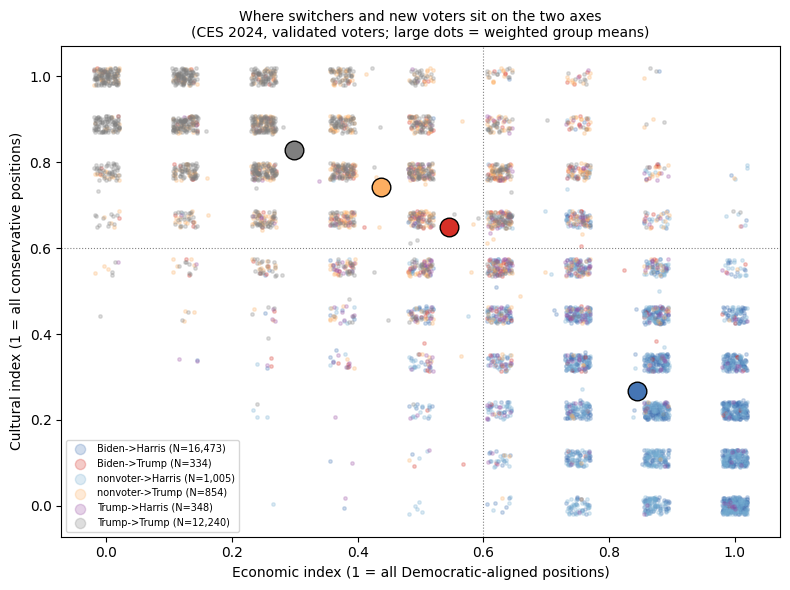

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
pal = {'Biden->Harris': '#4575b4', 'Biden->Trump': '#d73027', 'nonvoter->Trump': '#fdae61', 'nonvoter->Harris': '#74add1', 'Trump->Trump': '#7f7f7f', 'Trump->Harris': '#984ea3'}
for p in paths:
    s = e[e['path'] == p].sample(min(1500, (e['path'] == p).sum()), random_state=1)
    ax.scatter(s['econ_left'] + np.random.uniform(-.02, .02, len(s)), s['cult_cons'] + np.random.uniform(-.02, .02, len(s)), s=6, alpha=.25, color=pal[p], label=f'{p} (N={int((e["path"] == p).sum()):,})')
for p in ['Biden->Harris', 'Biden->Trump', 'nonvoter->Trump', 'Trump->Trump']:
    ax.scatter(profiles.loc[p, 'econ_left'], profiles.loc[p, 'immig_cons'] * 5 / 9 + profiles.loc[p, 'social_cons'] * 2 / 9 + profiles.loc[p, 'police_cons'] * 2 / 9, s=180, color=pal[p], edgecolor='black', zorder=5)
ax.axvline(.6, color='gray', ls=':', lw=.8); ax.axhline(.6, color='gray', ls=':', lw=.8)
ax.set_xlabel('Economic index (1 = all Democratic-aligned positions)'); ax.set_ylabel('Cultural index (1 = all conservative positions)')
ax.set_title('Where switchers and new voters sit on the two axes\n(CES 2024, validated voters; large dots = weighted group means)', fontsize=10)
ax.legend(fontsize=7, loc='lower left', markerscale=3); plt.tight_layout()
plt.savefig(FIGURES_DIR / 'switchers_two_axes.png', dpi=150, bbox_inches='tight'); plt.show()

## 6. Save

In [10]:
decomp.to_csv(TABLES_DIR / 'share_decomposition.csv'); profiles.to_csv(TABLES_DIR / 'issue_profiles_by_path.csv'); by_item.to_csv(TABLES_DIR / 'issue_items_by_path.csv')
pd.concat([sw_models, sw_se], axis=1).to_csv(TABLES_DIR / 'switch_issue_models.csv'); nv_model.to_csv(TABLES_DIR / 'newvoter_issue_model.csv')
quad_tab.to_csv(TABLES_DIR / 'quadrant_by_path.csv'); quad_switch.to_csv(TABLES_DIR / 'quadrant_switch_rates.csv')
print('Saved tables to outputs/tables/ and figure to outputs/figures/switchers_two_axes.png')

Saved tables to outputs/tables/ and figure to outputs/figures/switchers_two_axes.png


## Limitations

- **No messaging variable.** Whether Harris "accepted" a framing is not observable here. What is observable is what leavers believed and how far left they placed her.
- **No transgender, "wokeness," salience, minimum-wage, Medicare-for-all, or tariff items** in the 2024 common content. The cultural index is immigration (5 items), abortion and same-sex marriage (2), policing (2). The economic index is healthcare, taxes, student loans, and housing (8).
- **Attitudes are measured in 2024**, after the choice. A switcher's 2024 immigration views could be a consequence of switching as much as a cause. The panel has 2020 and 2022 attitudes for the same items but only 39 switchers.
- **Recalled 2020 vote** for the cross-section; the "Biden 2020 voters" group is subject to recall bias.
- **Indices are equal-weighted item averages.** Different weightings move the numbers somewhat; the axis ordering (cultural > economic for switching) is not sensitive to it.